# `Geocroissant` on Kaggle 🥐

## Introduction

<div style="display: flex; justify-content: space-between; align-items: center; gap: 24px;">
  <div>
    <p style="margin-top: 0;">In this tutorial, we curate and load the <b>Massachusetts Roads Dataset</b> hosted on Kaggle using <a href="https://github.com/mlcommons/croissant"><code>mlcroissant</code></a> and PyTorch to:</p>
    <ol style="margin-bottom: 0;">
      <li>Define GeoCroissant metadata in Python.</li>
      <li>Validate the metadata file.</li>
      <li>Stream the dataset into a PyTorch <code>DataLoader</code> and visualize it.</li>
    </ol>
  </div>
  <img src="../assets/geocr.jpg" alt="GeoCroissant" width="105" style="border-radius: 8px; flex-shrink: 0;">
</div>

In [1]:
#!pip install mlcroissant kagglehub

import json
import kagglehub
import mlcroissant as mlc
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import IterableDataset, DataLoader
import matplotlib.pyplot as plt

## Define the GeoCroissant metadata

We use the [Massachusetts Roads Dataset](https://www.kaggle.com/datasets/balraj98/massachusetts-roads-dataset) from Kaggle. It contains aerial images covering over 2,600 square kilometers across Massachusetts, paired with road centerlines.


In [2]:
# 1. Define FileObject for the remote Kaggle archive
archive = mlc.FileObject(
    id="archive.zip",
    name="archive.zip",
    description=(
        "Zip archive containing all contents of the Massachusetts Roads Dataset from"
        " Kaggle"
    ),
    content_url="https://www.kaggle.com/api/v1/datasets/download/balraj98/massachusetts-roads-dataset",
    encoding_formats=["application/zip"],
    md5="ziCW3X2WUi4b2WE55xg4/g==",
)

# 2. FileObjects for label dictionary and metadata CSVs inside archive
label_class_file = mlc.FileObject(
    id="label_class_dict.csv",
    name="label_class_dict.csv",
    description="Contains RGB color code mappings for road segmentation classes",
    contained_in=["archive.zip"],
    content_url="label_class_dict.csv",
    encoding_formats=["text/csv"],
    md5="e833449f9ab7e06e1647c121306ede73",
)

metadata_file = mlc.FileObject(
    id="metadata.csv",
    name="metadata.csv",
    description=(
        "Contains tile IDs, splits (train/val/test), source URLs, and file paths."
    ),
    contained_in=["archive.zip"],
    content_url="metadata.csv",
    encoding_formats=["text/csv"],
    md5="d82f039d4266355b23d8826342656086",
)

# 3. FileSets define resources inside the archive
distribution = [
    archive,
    label_class_file,
    metadata_file,
    mlc.FileSet(
        id="tiff",
        name="tiff",
        description="All GeoTIFF aerial imagery and road label masks across all splits",
        contained_in=["archive.zip"],
        encoding_formats=["image/tiff"],
        includes=["tiff/**/*"],
    ),
    mlc.FileSet(
        id="train",
        name="train",
        description="Training aerial RGB imagery",
        contained_in=["archive.zip"],
        encoding_formats=["image/tiff"],
        includes=["tiff/train/*.tiff"],
    ),
    mlc.FileSet(
        id="train_labels",
        name="train_labels",
        description="Training road segmentation masks",
        contained_in=["archive.zip"],
        encoding_formats=["image/tiff"],
        includes=["tiff/train_labels/*.tif"],
    ),
    mlc.FileSet(
        id="val",
        name="val",
        description="Validation aerial RGB imagery",
        contained_in=["archive.zip"],
        encoding_formats=["image/tiff"],
        includes=["tiff/val/*.tiff"],
    ),
    mlc.FileSet(
        id="val_labels",
        name="val_labels",
        description="Validation road segmentation masks",
        contained_in=["archive.zip"],
        encoding_formats=["image/tiff"],
        includes=["tiff/val_labels/*.tif"],
    ),
    mlc.FileSet(
        id="test",
        name="test",
        description="Test aerial RGB imagery",
        contained_in=["archive.zip"],
        encoding_formats=["image/tiff"],
        includes=["tiff/test/*.tiff"],
    ),
    mlc.FileSet(
        id="test_labels",
        name="test_labels",
        description="Test road segmentation masks",
        contained_in=["archive.zip"],
        encoding_formats=["image/tiff"],
        includes=["tiff/test_labels/*.tif"],
    ),
]


# Helper function to create standard RecordSets per split
def create_split_record_sets(split_name, img_id, mask_id):
    return [
        mlc.RecordSet(
            id=f"{split_name}_images",
            name=f"{split_name} images",
            spatial_resolution=mlc.QuantitativeValue(value=1.0, unitText="m"),
            fields=[
                mlc.Field(
                    id=f"{split_name}/filename",
                    name="filename",
                    data_types=[mlc.DataType.TEXT],
                    source=mlc.Source(
                        file_set=img_id,
                        extract=mlc.Extract(file_property="filename"),
                    ),
                ),
                mlc.Field(
                    id=f"{split_name}/image",
                    name="image",
                    data_types=[mlc.DataType.IMAGE_OBJECT],
                    is_array=True,
                    array_shape="1500,1500,3",
                    band_configuration=mlc.BandConfiguration(
                        total_bands=3, band_names_list=["Red", "Green", "Blue"]
                    ),
                    source=mlc.Source(
                        file_set=img_id,
                        extract=mlc.Extract(file_property="content"),
                    ),
                ),
            ],
        ),
        mlc.RecordSet(
            id=f"{split_name}_masks",
            name=f"{split_name} masks",
            fields=[
                mlc.Field(
                    id=f"{split_name}/mask_filename",
                    name="mask_filename",
                    data_types=[mlc.DataType.TEXT],
                    source=mlc.Source(
                        file_set=mask_id,
                        extract=mlc.Extract(file_property="filename"),
                    ),
                ),
                mlc.Field(
                    id=f"{split_name}/mask",
                    name="mask",
                    data_types=[mlc.DataType.IMAGE_OBJECT],
                    is_array=True,
                    array_shape="1500,1500,1",
                    band_configuration=mlc.BandConfiguration(
                        total_bands=1, band_names_list=["road_mask"]
                    ),
                    source=mlc.Source(
                        file_set=mask_id,
                        extract=mlc.Extract(file_property="content"),
                    ),
                ),
            ],
        ),
        mlc.RecordSet(
            id=f"{split_name}_examples",
            name=f"{split_name} examples",
            fields=[
                mlc.Field(
                    id=f"{split_name}_examples/image_key",
                    name="image_key",
                    data_types=[mlc.DataType.TEXT],
                    source=mlc.Source(
                        field=f"{split_name}/filename",
                        transforms=[mlc.Transform(regex=r"^(.+?)(?:\.tiff)?$")],
                    ),
                    references=mlc.Source(
                        field=f"{split_name}/mask_filename",
                        transforms=[mlc.Transform(regex=r"^(.+?)(?:\.tif)?$")],
                    ),
                ),
                mlc.Field(
                    id=f"{split_name}_examples/image",
                    name="image",
                    data_types=[mlc.DataType.IMAGE_OBJECT],
                    is_array=True,
                    array_shape="1500,1500,3",
                    band_configuration=mlc.BandConfiguration(
                        total_bands=3, band_names_list=["Red", "Green", "Blue"]
                    ),
                    source=mlc.Source(field=f"{split_name}/image"),
                ),
                mlc.Field(
                    id=f"{split_name}_examples/mask",
                    name="mask",
                    data_types=[mlc.DataType.IMAGE_OBJECT],
                    is_array=True,
                    array_shape="1500,1500,1",
                    band_configuration=mlc.BandConfiguration(
                        total_bands=1, band_names_list=["road_mask"]
                    ),
                    source=mlc.Source(field=f"{split_name}/mask"),
                ),
            ],
        ),
    ]


# Define RecordSets for class dictionary and metadata table
record_sets = [
    mlc.RecordSet(
        id="label_class_dict",
        name="label_class_dict",
        description="Color codes for road and background classes",
        fields=[
            mlc.Field(
                id="label_class_dict/name",
                name="name",
                data_types=[mlc.DataType.TEXT],
                source=mlc.Source(
                    file_object="label_class_dict.csv",
                    extract=mlc.Extract(column="name"),
                ),
            ),
            mlc.Field(
                id="label_class_dict/r",
                name="r",
                data_types=[mlc.DataType.INTEGER],
                source=mlc.Source(
                    file_object="label_class_dict.csv", extract=mlc.Extract(column="r")
                ),
            ),
            mlc.Field(
                id="label_class_dict/g",
                name="g",
                data_types=[mlc.DataType.INTEGER],
                source=mlc.Source(
                    file_object="label_class_dict.csv", extract=mlc.Extract(column="g")
                ),
            ),
            mlc.Field(
                id="label_class_dict/b",
                name="b",
                data_types=[mlc.DataType.INTEGER],
                source=mlc.Source(
                    file_object="label_class_dict.csv", extract=mlc.Extract(column="b")
                ),
            ),
        ],
    ),
    mlc.RecordSet(
        id="metadata",
        name="metadata",
        description="Metadata index table from metadata.csv",
        fields=[
            mlc.Field(
                id="metadata/image_id",
                name="image_id",
                data_types=[mlc.DataType.TEXT],
                source=mlc.Source(
                    file_object="metadata.csv", extract=mlc.Extract(column="image_id")
                ),
            ),
            mlc.Field(
                id="metadata/split",
                name="split",
                data_types=[mlc.DataType.TEXT],
                source=mlc.Source(
                    file_object="metadata.csv", extract=mlc.Extract(column="split")
                ),
            ),
            mlc.Field(
                id="metadata/image_souce_url",
                name="image_souce_url",
                data_types=[mlc.DataType.TEXT],
                source=mlc.Source(
                    file_object="metadata.csv",
                    extract=mlc.Extract(column="image_souce_url"),
                ),
            ),
            mlc.Field(
                id="metadata/label_source_url",
                name="label_source_url",
                data_types=[mlc.DataType.TEXT],
                source=mlc.Source(
                    file_object="metadata.csv",
                    extract=mlc.Extract(column="label_source_url"),
                ),
            ),
            mlc.Field(
                id="metadata/tiff_image_path",
                name="tiff_image_path",
                data_types=[mlc.DataType.TEXT],
                source=mlc.Source(
                    file_object="metadata.csv",
                    extract=mlc.Extract(column="tiff_image_path"),
                ),
            ),
            mlc.Field(
                id="metadata/tif_label_path",
                name="tif_label_path",
                data_types=[mlc.DataType.TEXT],
                source=mlc.Source(
                    file_object="metadata.csv",
                    extract=mlc.Extract(column="tif_label_path"),
                ),
            ),
            mlc.Field(
                id="metadata/png_image_path",
                name="png_image_path",
                data_types=[mlc.DataType.TEXT],
                source=mlc.Source(
                    file_object="metadata.csv",
                    extract=mlc.Extract(column="png_image_path"),
                ),
            ),
            mlc.Field(
                id="metadata/png_label_path",
                name="png_label_path",
                data_types=[mlc.DataType.TEXT],
                source=mlc.Source(
                    file_object="metadata.csv",
                    extract=mlc.Extract(column="png_label_path"),
                ),
            ),
        ],
    ),
]

for s_name, img_id, m_id in [
    ("train", "train", "train_labels"),
    ("val", "val", "val_labels"),
    ("test", "test", "test_labels"),
]:
    record_sets.extend(create_split_record_sets(s_name, img_id, m_id))

metadata = mlc.Metadata(
    name="massachusetts-roads-dataset",
    description=(
        "High-quality aerial imagery dataset for road segmentation covering urban,"
        " suburban, and rural areas across Massachusetts. Contains 1,171 aerial images"
        " of 1500x1500 pixels at 1 meter per pixel resolution, paired with rasterized"
        " road centerlines from OpenStreetMap."
    ),
    cite_as="""@phdthesis{MnihThesis,
    author = {Volodymyr Mnih},
    title = {Machine Learning for Aerial Image Labeling},
    school = {University of Toronto},
    year = {2013}}""",
    conforms_to=[
        "http://mlcommons.org/croissant/1.1",
        "http://mlcommons.org/croissant/geo/",
    ],
    coordinate_reference_system="EPSG:26986",
    date_published="2020-09-26",
    keywords=[
        "remote sensing",
        "aerial imagery",
        "road segmentation",
        "geospatial",
        "massachusetts",
        "computer vision",
    ],
    license="https://creativecommons.org/licenses/by/4.0/",
    sampling_strategy=(
        "1500x1500 aerial tiles covering 2.25 square kilometers each, rescaled to 1"
        " pixel per square meter."
    ),
    spatial_bias=(
        "Concentrated over Massachusetts, USA covering over 2,600 square kilometers"
        " across urban, suburban, and rural regions."
    ),
    spatial_resolution=mlc.QuantitativeValue(value=1.0, unitText="m"),
    band_configuration=mlc.BandConfiguration(
        total_bands=3, band_names_list=["Red", "Green", "Blue"]
    ),
    spectral_band_metadata=[
        mlc.SpectralBand(
            name="Red",
            center_wavelength=mlc.QuantitativeValue(value=650, unitText="nm"),
            bandwidth=mlc.QuantitativeValue(value=100, unitText="nm"),
        ),
        mlc.SpectralBand(
            name="Green",
            center_wavelength=mlc.QuantitativeValue(value=550, unitText="nm"),
            bandwidth=mlc.QuantitativeValue(value=100, unitText="nm"),
        ),
        mlc.SpectralBand(
            name="Blue",
            center_wavelength=mlc.QuantitativeValue(value=450, unitText="nm"),
            bandwidth=mlc.QuantitativeValue(value=100, unitText="nm"),
        ),
    ],
    spatial_coverage={
        "@type": "Place",
        "geo": {
            "@type": "GeoShape",
            "box": "41.869217 -72.740693 42.794047 -70.614044",
        },
    },
    url="https://www.kaggle.com/datasets/balraj98/massachusetts-roads-dataset",
    version="1.0.0",
    distribution=distribution,
    record_sets=record_sets,
)

print("metadata instantiated")

metadata instantiated


In [3]:
# 4. Serialize to JSON-LD
metadata_json = metadata.to_json()
metadata_json["@context"]["containedIn"] = "cr:containedIn"

output_json = "massachusetts-roads-dataset-metadata.json"
with open(output_json, "w") as f:
    json.dump(metadata_json, f, indent=2)

print(f"metadata saved to {output_json}")

metadata saved to massachusetts-roads-dataset-metadata.json


## Validate the metadata

We check the saved `massachusetts-roads-dataset-metadata.json` file with the `mlcroissant` command-line validator to confirm it follows the specification:


In [4]:
# validate using mlcroissant
!mlcroissant validate --jsonld=massachusetts-roads-dataset-metadata.json

I1106 22:40:53.594930 133009193658176 validate.py:53] Done.


## Load the dataset and visualize

We ensure the remote Kaggle archive is downloaded and cached via `kagglehub`, then load it using `mlcroissant`:


In [5]:
# 5. Load using mlcroissant
data_dir = kagglehub.dataset_download("balraj98/massachusetts-roads-dataset")
print(f"Kaggle data cached at: {data_dir}")

dataset = mlc.Dataset(
    jsonld="massachusetts-roads-dataset-metadata.json",
    mapping={"archive.zip": data_dir},
)
print("Dataset loaded successfully")

meta = dataset.metadata
print(f"Dataset Name: {meta.name}")
for k, v in meta.extra_properties.items():
    print(f"{k}: {v}")

Kaggle data cached at: /home/xuan/.cache/kagglehub/datasets/balraj98/massachusetts-roads-dataset/versions/1
Dataset loaded successfully
Dataset Name: massachusetts-roads-dataset


In [6]:
# 6. PyTorch Loader
class RoadDataPipe(IterableDataset):
    def __init__(self, dataset_or_path, record_set_id="val_examples", mapping=None):
        if isinstance(dataset_or_path, str):
            self.dataset = mlc.Dataset(dataset_or_path, mapping=mapping)
        else:
            self.dataset = dataset_or_path
        self.record_set_id = record_set_id

    def __iter__(self):
        records = self.dataset.records(self.record_set_id)
        for record in records:
            img_pil = record[f"{self.record_set_id}/image"]
            mask_pil = record[f"{self.record_set_id}/mask"]

            # Normalize RGB image [H, W, C] -> [C, H, W]
            img_np = np.array(img_pil, dtype=np.float32) / 255.0
            img_tensor = torch.tensor(img_np).permute(2, 0, 1)

            # Binary mask: 1 for road, 0 for background
            mask_np = (np.array(mask_pil) > 0).astype(np.float32)
            mask_tensor = torch.tensor(mask_np).unsqueeze(0)

            yield {
                "image_key": record[f"{self.record_set_id}/image_key"],
                "image": img_tensor,
                "mask": mask_tensor,
            }


print("PyTorch loader defined!")

PyTorch loader defined!


In [7]:
# 7. Loader and iterate records
datapipe = RoadDataPipe(dataset, "val_examples")
loader = DataLoader(datapipe, batch_size=1)

print("Iterating over PyTorch DataLoader...")
records_list = []
for i, batch in enumerate(loader):
    print(f"Record {i} loaded:")
    print(f"  Key: {batch['image_key'][0]}")
    print(f"  Image shape: {batch['image'].shape}")
    print(f"  Mask shape: {batch['mask'].shape}")

    # Keep records for visualization
    records_list.append(batch)
    if len(records_list) >= 3:
        break

Iterating over PyTorch DataLoader...
Record 0 loaded:
  Key: b'10228690_15'
  Image shape: torch.Size([1, 3, 1500, 1500])
  Mask shape: torch.Size([1, 1, 1500, 1500])
Record 1 loaded:
  Key: b'10978735_15'
  Image shape: torch.Size([1, 3, 1500, 1500])
  Mask shape: torch.Size([1, 1, 1500, 1500])
Record 2 loaded:
  Key: b'10978795_15'
  Image shape: torch.Size([1, 3, 1500, 1500])
  Mask shape: torch.Size([1, 1, 1500, 1500])


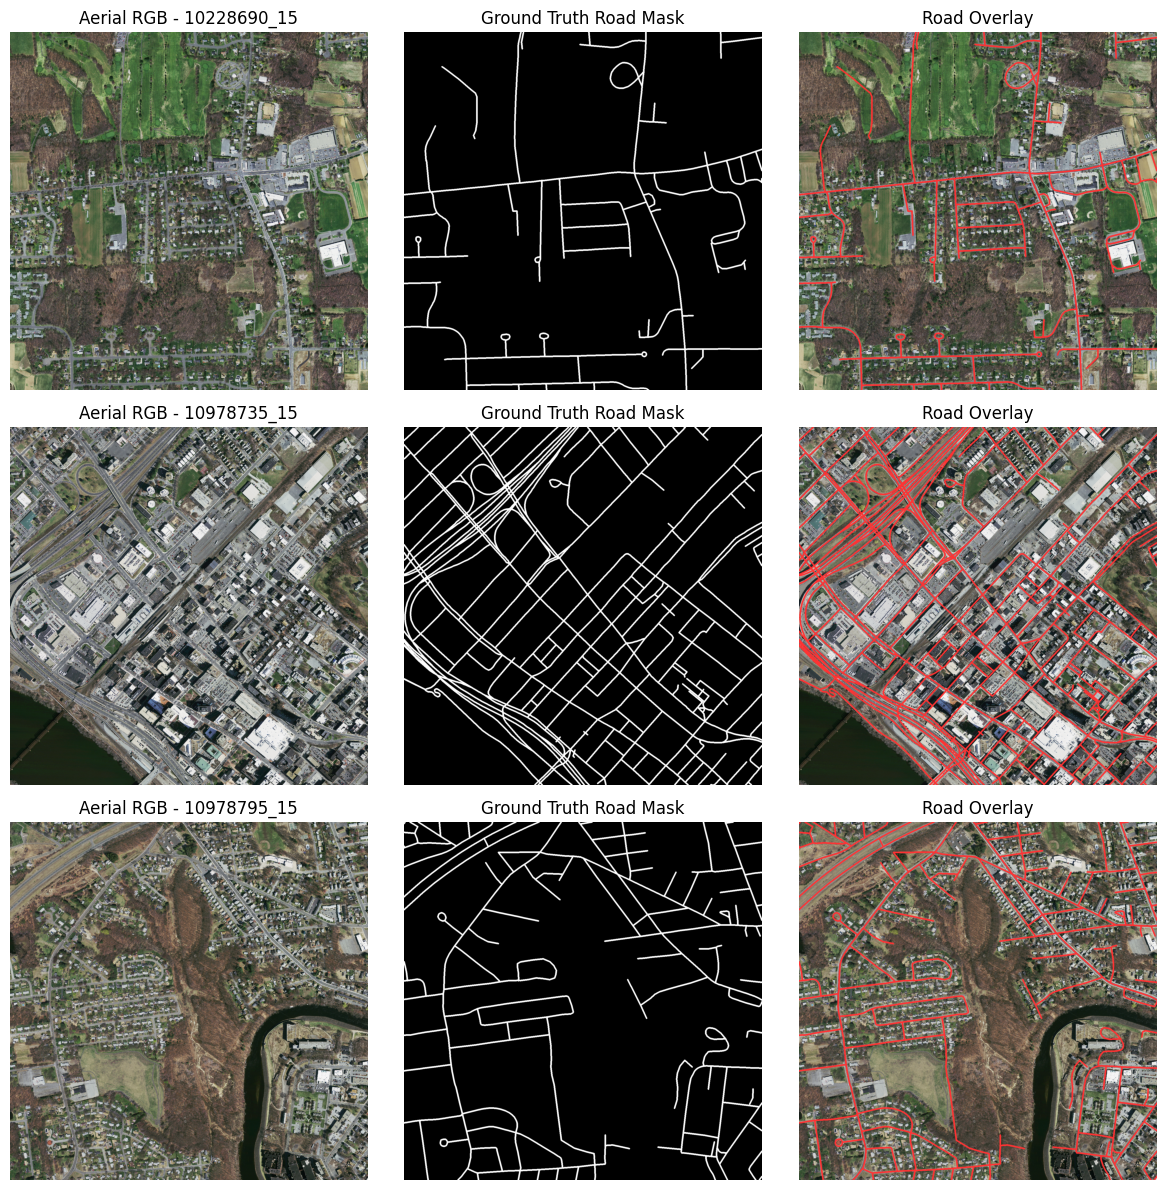

In [8]:
# 8. Visualizing image and mask
fig, axes = plt.subplots(3, 3, figsize=(12, 12), facecolor="white")

for idx, batch in enumerate(records_list):
    # batch['image'] has shape [1, 3, 1500, 1500] -> remove batch dimension
    img = batch["image"][0].permute(1, 2, 0).numpy()
    mask = batch["mask"][0, 0].numpy()
    key_name = batch["image_key"][0].decode("utf-8")

    # Plot Aerial RGB
    axes[idx, 0].imshow(img)
    axes[idx, 0].set_title(f"Aerial RGB - {key_name}", color="black")
    axes[idx, 0].axis("off")

    # Plot Road Mask
    axes[idx, 1].imshow(mask, cmap="gray", vmin=0, vmax=1)
    axes[idx, 1].set_title("Ground Truth Road Mask", color="black")
    axes[idx, 1].axis("off")

    # Plot Overlay (highlight road pixels in red)
    overlay = img.copy()
    overlay[mask > 0] = [1.0, 0.2, 0.2]
    axes[idx, 2].imshow(overlay)
    axes[idx, 2].set_title("Road Overlay", color="black")
    axes[idx, 2].axis("off")

plt.tight_layout()
plt.show()